
**AOTUENCODERS**


In [13]:
import pandas as pd
import numpy as np
from keras.models import Model
from keras.layers import Input,Dense
from keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import json,codecs
import warnings
warnings.filterwarnings("ignore")


In [19]:
(x_train, _),(x_test,_) = fashion_mnist.load_data()

In [20]:
x_train = x_train.astype("float32") /255.0
x_test = x_test.astype("float32") /255.0

In [21]:
x_train.shape

(60000, 28, 28)

In [16]:
x_train = x_train.reshape((len(x_train),x_train.shape[1:][0]*x_train.shape[1:][1]))


In [17]:
x_train.shape 

(60000, 784)

In [5]:
x_test = x_test.reshape((len(x_test),x_test.shape[1:][0]*x_test.shape[1:][1]))

In [ ]:
x_test.shape

In [6]:
x_train.shape

(60000, 784)

(<matplotlib.image.AxesImage at 0x7fe8ea7ab310>,
 (-0.5, 27.5, 27.5, -0.5),
 <function matplotlib.pyplot.show>)

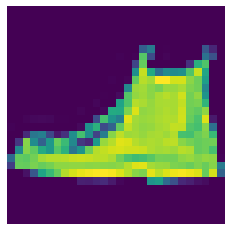

In [7]:
plt.imshow(x_train[450].reshape(28,28)),plt.axis("off"),plt.show

In [8]:
input_img = Input(shape = (784,))
eccoded = Dense(32,activation = "relu")(input_img )
eccoded = Dense(16,activation = "relu")(eccoded)

decoded  = Dense(32,activation = "relu")(eccoded)
decoded  = Dense(784,activation = "sigmoid")(eccoded)

autoencoder = Model(input_img,decoded)

In [9]:
autoencoder.compile(optimizer = "rmsprop",loss = "binary_crossentropy")

In [10]:
hist = autoencoder.fit(x_train,x_train , epochs = 200 , batch_size= 256 ,shuffle = True , validation_data = (x_train,x_train) )

Epoch 1/200
235/235 [==============================] - 4s 15ms/step - loss: 0.4094 - val_loss: 0.3506
Epoch 2/200
235/235 [==============================] - 3s 14ms/step - loss: 0.3369 - val_loss: 0.3279
Epoch 3/200
 69/235 [=======>......................] - ETA: 1s - loss: 0.3273

In [ ]:
autoencoder.save_weights("autocoder_model.h5")

In [ ]:
print(hist.history.keys())

In [ ]:
plt.plot(hist.history["loss"],label = "train loss")
plt.plot(hist.history["val_loss"],label = "validation loss")
plt.legend()
plt.show()

In [ ]:
with open("autoencoders_hist.json","w") as f:
  json.dump(hist.history,f)

In [ ]:
with codecs.open("/content/drive/MyDrive/autoencoders_hist.json","r",encoding = "utf-8") as f :
  n = json.loads(f.read())

In [ ]:
plt.plot(n["loss"],label = "train loss")
plt.plot(n["val_loss"],label = "validation loss")
plt.legend()
plt.show()

In [ ]:
 encoder = Model(input_img,eccoded)
 encoded_img = encoder.predict(x_test)



In [ ]:
plt.imshow(x_test[1500].reshape(28,28))
plt.axis("off")
plt.show()

In [ ]:
plt.figure()
plt.imshow( encoded_img [1500].reshape(4,4))
plt.axis("off")
plt.show()

In [ ]:
decoded_img = autoencoder.predict(x_test)

In [ ]:
n = 10
plt.figure(figsize=(20,4))

for i in range(n):
  ax = plt.subplot(2,n,i+1)
  plt.imshow(x_test[i].reshape(28,28))
  plt.axis("off")


  ax = plt.subplot(2,n,i + n+1)
  plt.imshow(decoded_img[i].reshape(28,28))
  plt.axis("off")
plt.show()